# More exploration and development of the analytic-response sensitivity calculation

We have been seeing this not completely agreeing, but we don't know why.

## 0. Necessary installations

Installation of the LISA Simulation suite is required, just like in the workshop:

    #These may be outdated
    pip install numpy scipy sympy h5py matplotlib xarray h5py scikit-learn
    pip install git+https://gitlab.in2p3.fr/lisa-simulation/constants.git@latest
    pip install git+https://gitlab.in2p3.fr/lisa-simulation/instrument.git@latest
    pip install git+https://gitlab.in2p3.fr/lisa-simulation/gw-response.git@latest
    pip install pytdi
    pip install backgrounds

In [1]:
import jax
jax.config.update("jax_enable_x64", True)  #HACK: Some things are coming up zeros with jax, maybe this helps

import importlib
import os
from datetime import datetime

import json
import h5py
import numpy as np
import scipy
import matplotlib.pyplot as plt

from pytdi import Data

from pcipy.data import TimeData
from pcipy.pci_filter import PCIFilter
from pcipy.filter import PiecewiseFilter as PiecewiseFilter
from pcipy.local_pci_filter import LocalPCIFilter
import pcipy.sensitivity as sensitivity

import pyfftw
from pyfftw.interfaces.numpy_fft import rfft

In [2]:
#1. Read in data sets
SKIP_HOURS = 4

RANGE_IN_HOURS = 24*14

DATADIR = "/Users/jbaker/Projects/PCI/late-2025-work/pcipy/data/"
WORKDIR = DATADIR+"/simulations/"

MEASPATH = 'measurements_4Hz.h5'
TDIPATH = 'tdi2_4Hz.h5'
ORBPATH = 'keplerian'

#LOCKING='N1-12'
LOCKING='six'

JITTER=''
substring = [ORBPATH + '_' +
             s for s in ['locking_'+LOCKING+'_laser_tm_oms_', 'all_sky_gw_', 'gw_']]
# substring = ['locking_six_laser_tm_oms', 'all_sky_gw', '2_gw']
sims = ["noise", "all_sky", "point_source"]
datasets = dict(zip(sims, substring))

matchfile = {}
dtpath = {}

for n, d in zip(substring, datasets):
    timestamp = []
    matchfile[n] = [f for f in os.listdir(WORKDIR) if n in f]
    for m in matchfile[n]:
        # pick latest date
        timestamp.append(datetime.strptime(m[:11], "%Y-%m-%d_"))
        # print(n, timestamp[n])
        dtpath[d] = max(timestamp).strftime("%Y-%m-%d_")
print(dtpath)

orbits = WORKDIR + ORBPATH + "-orbits.h5"
noise_file_base = dtpath['noise'] + datasets['noise']
gw_file_base = dtpath['all_sky'] + datasets['all_sky']
#gw_file_base = dtpath['point_source'] + datasets['point_source']

{'noise': '2026-05-31_', 'all_sky': '2025-12-02_', 'point_source': '2025-12-02_'}


In [3]:
#2. Generate Basic single-link noise data

noise_sim_path = WORKDIR + noise_file_base + MEASPATH

# get the central frequency
with h5py.File(noise_sim_path, 'r') as sim:
    attributes = json.loads(sim.attrs['metadata_json'])
    central_freq = attributes['central_freq']
    fs = attributes['fs']

data_noise = Data.from_instrument(noise_sim_path)

in_chans = ["sci"]
#in_chans = ["sci", "ref", "tmi"]
# in_chans=["isi","rfi","tmi","isi_sb","rfi_sb"]

in_chansGW = ["sci"]

def make_names(in_chans):
    """

    Parameters
    ----------
    in_chans : TYPE
        DESCRIPTION.

    Returns
    -------
    names : TYPE
        DESCRIPTION.

    """
    mosas_order = ['12', '23', '31', '13', '21', '32']
    names = []
    for chan in in_chans:
        for link in mosas_order:
            names.append(f'{chan}_{link}')
    return names


SKIP = int(SKIP_HOURS * 3600 * fs)
print(SKIP)

# setup instrumental channels
y_names = make_names(in_chans)
# divide by central_freq because simulation channels are in beat-rate units
y_list = [data_noise.measurements[name]/central_freq for name in y_names]
# create a TimeData object
y_n = TimeData(np.array(y_list, dtype=np.float64)[:, SKIP:],
               dt=1/fs,
               t0=SKIP/fs,
               names=y_names)


# In[4]: 3.2 Matching GW simulations results for the empirical sensitivity calculation

# we need these only for the sensitivity calculation

gw_path = WORKDIR+gw_file_base+MEASPATH

data_gw = Data.from_gws(gw_path,orbits)

y_namesGW = make_names(in_chansGW)
# #note: the GW mesaurement data are already fractional frequency so we don't divide by central_freq
y_list = [data_gw.measurements[name] for name in y_namesGW]
print(y_list)
np.array(y_list, dtype=np.float64)
y_gw = TimeData(np.array(y_list, dtype=np.float64)[:,SKIP:],dt=1/fs,t0=SKIP/fs,names=y_namesGW)


You are using a GW file in a version that might not be fully supported


57600


You are using an orbit file in a version that might not be fully supported


[array([-1.41632032, -0.69311517,  0.77876657, ...,  0.39048086,
       -1.09957272,  1.19657138], shape=(1036800,)), array([ 1.59617394, -0.01736913,  0.17493602, ...,  0.22864093,
       -0.83424273, -0.50197507], shape=(1036800,)), array([-0.06541711, -0.32268751, -1.89618023, ..., -0.6444277 ,
       -1.50888836,  0.47132676], shape=(1036800,)), array([-0.0071528 ,  0.28215591, -0.91863577, ...,  0.66760965,
        0.41628684,  0.07508159], shape=(1036800,)), array([-0.00471052,  0.8045424 ,  0.27495304, ..., -0.79777095,
       -0.31748646, -0.21881929], shape=(1036800,)), array([-0.68682979,  0.241871  , -0.78731567, ..., -0.40345769,
        1.54841282,  0.00750714], shape=(1036800,))]


In [4]:
#hack to adapt to older notation below (FIXME)
y_full=y_n.data.T
skip=300
print(y_full.shape)

(979200, 6)


## Sensitivity

So far, the rest of this notebook is no longer the further restructured version of the previous notebook, but really a development effort for the sensitivity calculation.  TBD move this to a new notebook.

### So far we do not understand what is happening with the sensitivity calculation. 

Both the empirical and the backgrounds-based calculations are yielding sensitivity estimates which are far too low.  

There are a few effects that we at least partially understand.

 - When the Welch P/CSD nperseg value is too high (less smoothing) the sensitivity often comes out underestimated.  In our case we see this, sometimes to an extreme degree, but for small nperseg, the sensitivity still saturates at about few e-28 levels.
 - There could be issues with the new backgrounds-based calculation which doesn't rely on a simulation of the GW response.  However, when the Welch estimate issue is controlled, we do see approximate agreement.  Note that the backgrounds-based calculation may be more strongly affected by inaccurate CSD computation because the GW-response part is computed analytically (no Welch estimation).
 - There is another similar notebook/script (pci-single-noise) which at least shows approximate agreement of the PCI sensitivity.  Understanding the difference there may be key. Here are some differences:
   - The other script does not use the new generic filter interface in LocalPCIFilter
   - The other script does not use the same sensitivity calculation code, but a closely related version, coded directly in the notebook
   - The other script does PCI the old way (on the eta channels)
   - We also note that the PCI variance found in this notebook have similar shape to those in the other notebook compressed into the first 2/3s of the components, but the last 3rd are about 15-18 orders of magnitude smaller 

In [5]:
# Function to help with applying the empirical sensitivity calculation in the same way to either native or LinearFilter versions of PCI
def apply_pci_filter(pcifilt,timedata):
    #unpack time data, apply the pcifilter natively, repack timedata
    outdata = pcifilt.apply_for_channels(timedata.data)
    return TimeData(outdata,dt=timedata.dt,t0=timedata.t0+pcifilt.nhalf*timedata.dt)
def change_names(timedata,inbase,outbase):
    assert(timedata.match_names(make_names([inbase]),verbose=True))
    return TimeData(timedata.data,dt=timedata.dt,t0=timedata.t0,names=make_names([outbase]))

#### Plan
  - Redo the LocalPCIFilter realization here mainly independent of the more wide-ranging code above
    - Also made the data size/range more closely match that in the other notebook
    - $\color{red}{\text{Done, no surprises or big effects}}$
    - Also played with number of channels.
    - $\color{red}{\text{For one channel (with nperseg=2000,hours=12) empirical and backgrounds estimates are quite similar} \textit{ except } \text{ for a factor of about 1.3 (empircal is higher) }}$
  - Try here with sci channels only
    - $\color{red}{\text{ Done, results look similar}}$
  - Try here PCI built the other way but compute the sensitivity
    - $\color{red}{\text{Implemented. We can reproduce the differences both ways now.}}$
  - Try PCIFilter, but with the sci channels
    - $\color{red}{\text{Here we also see the smae extra-small variances now with PCIFilter}}$
  - Try LocalPCIFilter, but with the eta channels
    - $\color{red}{\text{}}$
  - TBD
 

In [15]:
# TDI2 fractional delay Lagrange interpolating polynomials are of order 31=1+15*2
# Overall TDI delays are up to 8x single link delay = 8.34 s * 4 Hz * 8 = about 267 sample
# Add 15 on each end: 267 + 2*15 = 297   
# TDI2 overall stencil is then about 297 samples
# aPCI overall stencil width is 1 + nhalf*2
nhalf = 125
pci_regard_hours=4
ns = int(pci_regard_hours * 3600 * fs)
Tscale=10

ncompts=15
orderk=2

In [16]:
# redo LocalPCIFilter instantiation for more controlled testing:

in_chans = ["sci"]
more_in_chans = ["sci", "ref", "tmi"]
#in_chans=["isi","rfi","tmi","isi_sb","rfi_sb"]

pcifilt = LocalPCIFilter(data_noise, in_chans=in_chans, skip_secs=SKIP/fs, 
                                      pci_regard_hours=pci_regard_hours, 
                                      nhalf=nhalf, pci_order=orderk, n_compts=ncompts, 
                                      sort_by_rms=False,Tscale=Tscale, testPCI=True)   


iskip= 57600
prelim ieval,i0,pci_ns,data_ns: 28925 0 57600 1036800
final i0,pci_ns,data_ns: 0 57600 1036800
check t0: 0.0 14400.0
pci(): [[ 1112.14428169  1148.66482412  1061.33944291 ...   831.0916936
    652.43476964   773.18636104]
 [  804.28996174   781.9045391    881.04626531 ...  2747.08315845
   2788.82768457  2806.38723055]
 [ -677.37823291  -697.3445427   -638.44725667 ...  -762.20101865
   -913.27238904  -873.49764651]
 [  607.87615438   676.69703389   696.06564441 ...   891.56673768
    803.17351624   928.0395644 ]
 [-1234.39609409 -1163.4026493  -1243.72426839 ...  -644.12440372
   -663.54134287  -707.85494894]
 [ -883.88585982  -795.82282199  -836.52924277 ... -2751.26626812
  -2836.04196767 -2711.50420221]] 4.0 125 2 15 None None False False False 10 None None
(57600, 4518)
variance check rms: 4.587323178711607e-13
shapes of chans, cov, components: (15, 57600) (15, 15) (15, 4518)
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
channel covariance diagonality test on 15 comp

In [24]:
### Code copied and adapted for reference and analysis
def estimate_sensitivity(filt, data_n, orbits, e_gw_mat = None, joint=True, welch_kwargs=None, strainPSD=1.0, analytic = False, nsideGWB=12, use_TDI_design_matrix=False,gw_ch_base_name='sci'):
    """
    Estimate the sensitivity of a given dataset against the response to an isotropic SGWB.

    Sensitivity is estimated by explicit computation of the inverse trace of the ratio of the channel simulated GW signal and the channel noise. To scale the sensitivity, we need to know the incident strain PSD value (assumed constant here).

    Parameters
    ----------
    filt : Filter Class.
        If None, data are treated unfilteree.
    data_n : TimeData Class.
        Instrument noise data.
    orbits : str
        Path to orbit file.
    e_gw_mat : GW covariance, optional
        Precalculated GW response from a StochasticBackgroundResponse object from backgrounds. If None, the GW response is evaluated within the class, slowing down calculation time. The default is None.
    joint : bool, optional
        Calculate the joint sensitivity of all channels in the TimeData class. The default is True.
    welch_kwargs : dict, optional
        Dictionary of Welch kwargs for the evaluation of the noise CSD matrix. The default is None.
    strainPSD : float, optional
        Incident strain PSD value (assumed constant here). The default is 1.
    analytic : bool, optional
        Choose between analytic noise covariance matrix, w.r.t. numeric. The default is False.
    nside : float, optional
        Specify the heal-pix number nside value indicating the all-sky GW source density.
    use_TDI_design_matrix : bool, optional
        If true, use backgrounds package code to compute the transfer function from the design matrix instead of computing the transfer function from the filter kernel. Irrelevant if gw_mat is provided.
    gw_ch_base_name: string, optional
        Base name for the input channels with single-link GW response. Default is 'sci'.
    Returns
    -------
    freqs : ndarray
        Array of frequencies.
    sens : ndarray
        Array of sensitivity values. If joint == False, it's an array with as many columns as channels.
    """
    if filt is not None:
        e_n = filt.apply_filter(data_n,method='convolve')
    else:
        e_n = data_n

    if welch_kwargs is None:
        nperseg = e_n.n_samples()
        fs = 1/e_n.dt
        welch_kwargs = {"fs": fs,
                  "window": 'blackman',
                  "nperseg": nperseg,
                  "detrend": 'constant',
                  "return_onesided": True,
                  "scaling": 'density'}

    n_channels=e_n.n_channels()
    #print(n_channels,'channels')

    # Welch spectrum matrix from noise data
    freqs, e_n_mat = compute_welch_matrix_td(e_n, **welch_kwargs)

    # GW response to a SGWB background
    if e_gw_mat is None:
        nside = nsideGWB
        npix = hp.nside2npix(nside)
        # skymap = np.ones(npix) * np.sqrt(4 * np.pi / (2*npix))
        # skymap = np.ones(npix) / np.sqrt(4 * np.pi * npix)
        skymap = np.ones(npix) / np.sqrt(2 * npix)

        #  Instantiate SGWB class
        sgwbcls = StochasticBackgroundResponse(skymap=skymap, orbits=orbits, orbit_interp_order=1)
        sgwbcls_t0 = sgwbcls.orbits.t_interp[0]
        t0 = np.ones(1) * (sgwbcls_t0 + 10)  # need an object with a specific length
        # Now let's do it for all links
        gplus, gcross = sgwbcls.compute_correlations(LINKS, freqs, t0)
        bgresponse = gplus + gcross
        # compute TDI response matrix
        # Time delay interferometry performs a linear combination of delayed single-link measurements to cancel laser frequency noise. It outputs three channels that contain all the GW information.

        # Algebraically, this transformation can be written in the (time-)frequency domain using a matrix operation:
        # If you have already computed the single-link responses like above, you can simply compute the TDI transfer function (for X, Y, Z) and then apply it through the equation above:
        bgresponse_reordered = bgresponse[..., convert, :]
        bgresponse_reordered = bgresponse_reordered[..., convert]

        if use_TDI_design_matrix:
            # tdi transfer function at frequencies freqs and time t0
            # this is an array of 3 x 6 matrices (ncombs x nlinks)        
            designmat = sgwbcls.compute_tdi_design_matrix(freqs, t0, gen = '2.0')
            # compute the response in the frequency domain
            # this is an array of 3 x 3 matrices
            #  Rtdi = Mtdi * Rlinks * Mtdi'
            # (ncombs x ncombs) = (ncombs x nlinks) * (nlinks x nlinks) * (nlinks x ncombs)
            # tdiresponse
            e_gw_mat = utils.transform_covariance(designmat, bgresponse_reordered)
        else:
            #This probably shouldn't be hard coded, but left. We need to ensure that the links are in the right order
            gw_input_names= [gw_ch_base_name +'_'+ link for link in ['12', '23', '31', '13', '21', '32']]
            
            filtGW=filt.restrict(input_names=gw_input_names)
            #Note that we have not addressed the question that the design matrix evolves with time
            #The "tdi_design_matrix" approach uses just a point slightly after t0 as the reference time
            #The piecewise filter approach so far uses the central version of the filter.
            designmat = filtGW.compute_filter_transfer_func(freqs)
            # compute the response in the frequency domain
            # this is an array of 3 x 3 matrices
            #  Rout = Tranf * Rlinks * Transf'
            # (ncombs x ncombs) = (ncombs x nlinks) * (nlinks x nlinks) * (nlinks x ncombs)
            # I expected that I should be using bg_response not bg_response_reordered here, but the latter yields a result which mostly matches theTDI_design_matrix version ... This is probably because of the order of the links in the list above FIXME
            e_gw_mat = utils.transform_covariance(designmat, bgresponse_reordered)

    else:
        ##This looks like an unnecessary hack. Why is it here?
        nside = nsideGWB
        npix = hp.nside2npix(nside)
        # skymap = np.ones(npix) * np.sqrt(4 * np.pi / (2*npix))
        # skymap = np.ones(npix) / np.sqrt(4 * np.pi * npix)
        skymap = np.ones(npix) / np.sqrt(2 * npix)

        #  Instantiate SGWB class
        sgwbcls = StochasticBackgroundResponse(skymap=skymap, orbits=orbits, orbit_interp_order=1)
        t0 = np.ones(1) * (sgwbcls.t0 + 10)  # need an object with a specific length
        

    if analytic==True:
        # OMS amplitudes from LISA Instrument paper
        oms_asds=(6.35e-12, 1.25e-11, 1.42e-12, 3.38e-12, 3.32e-12, 7.90e-12)
        # root sum square of the carrier amplitudes
        Aoms= np.sqrt(oms_asds[0]**2+oms_asds[2]**2+oms_asds[4]**2)
        Atm = 2.24e-15
        noise_classes_analytic = []
        noise_classes_analytic.append(noise.AnalyticOMSNoiseModel(
            freqs, t0, orbits, orbit_interp_order=1, gen="2.0", fs=None, duration=None, oms_isi_carrier_asds=Aoms))
        noise_classes_analytic.append(noise.AnalyticTMNoiseModel(
            freqs, t0, orbits, orbit_interp_order=1, gen="2.0", fs=None, duration=None, tm_isi_carrier_asds=Atm))

        # Compute the TDI spectrum from OMS and TM noise
        cov_tdi_n_comps = [nc.compute_covariances(0.0) for nc in noise_classes_analytic]
        # Compute the full TDI noise spectrum
        e_n_mat = sum(cov_tdi_n_comps)

    # Output sensitivity for each variable, size nfreqs x n_channels
    sens = np.array([np.abs(e_n_mat[:, j, j] / e_gw_mat[:, j, j] * strainPSD) for j in range(n_channels)]).T

    if joint:
        e_n_mat_inv = np.linalg.inv(e_n_mat)
        #print('Calculate trace')
        sens = 1/np.trace(np.linalg.matmul(e_gw_mat,e_n_mat_inv), axis1=1, axis2=2)

    return freqs, sens


In [22]:
welch_kwargs = {"fs": fs,
          "window": 'blackman',
          "nperseg": 2000,
          "detrend": 'constant',
          "return_onesided": True,
          "scaling": 'density'}
welch_kwargs_detrend=dict(welch_args}
                         )
welch_kwargs['detrend']=None

welch_kwargs_1k=dict(welch_args)
welch_kwargs_1k['nperseg']=1000

welch_kwargs_4k=dict(welch_args)
welch_kwargs_4k['nperseg']=4000

ioff=0
ytest_n=y_n.get_range(ns*ioff,ns*(1+ioff)+2*nhalf)
ytest_gw=y_gw.get_range(ns*ioff,ns*(1+ioff)+2*nhalf)

nside = 5
sens_list = []
#sens_list += [['std-pci0,emp,chans', 
#     sensitivity.estimate_sensitivity_empirically(pcifilt,ytest_n,ytest_gw, strainPSD=2, gw_input_names=y_namesGW, joint=False,welch_kwargs=welch_kwargs)
#    ]]
#sens_list += [['std-pci0,bgs,chans', 
#     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=False,welch_kwargs=welch_kwargs,nsideGWB=nside)
#    ]]
sens_list += [['std-pci'+str(orderk)+',emp,joint', 
    sensitivity.estimate_sensitivity_empirically(pcifilt,ytest_n,ytest_gw, strainPSD=2, gw_input_names=make_names(['sci']), joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['std-pci'+str(orderk)+',native-emp,joint', 
     sensitivity.estimate_sensitivity_empirically(None,apply_pci_filter(pcifilt.pci_TEST,ytest_n),apply_pci_filter(pcifilt.pci_TEST,ytest_gw),strainPSD=2,joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['std-pci'+str(orderk)+',bgs,joint', 
     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside)
    ]]
sens_list += [['std-pci'+str(orderk)+',emp,joint', 
    sensitivity.estimate_sensitivity_empirically(pcifilt,ytest_n,ytest_gw, strainPSD=2, gw_input_names=make_names(['sci']), joint=True,welch_kwargs=welch_kwargs)
    ]]
sens_list += [['std-pci'+str(orderk)+',bgs-detrend,joint', 
     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside)
    ]]
#sens_list += [['std-pci0,nb-bgs,joint', 
#     estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,nsideGWB=nside)
#    ]]
#sens_list += [['tdi', 
#     sensitivity.estimate_sensitivity(pcifilt,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs,use_TDI_design_matrix=True,analytic=True,nsideGWB=nside)
#    ]]

/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


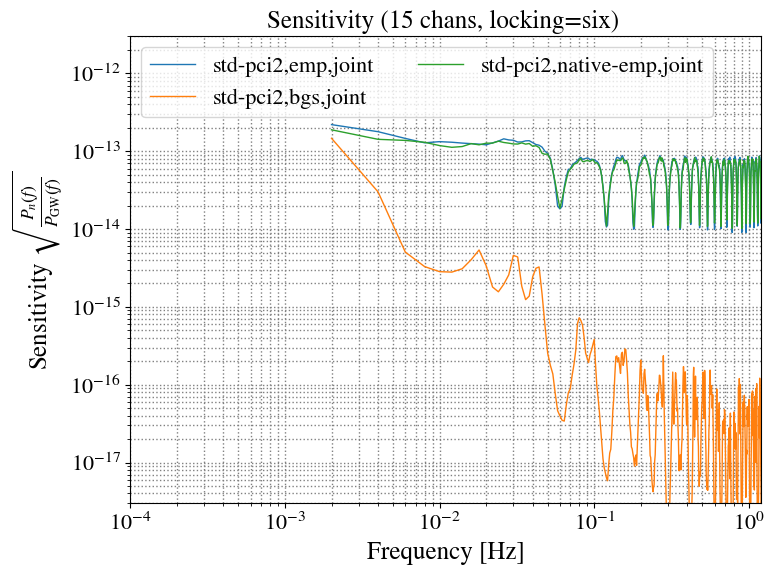

In [23]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))

for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-4, 1.2])
axes.set_ylim([3e-18, 3e-12])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity ("+str(ncompts)+" chans, locking="+LOCKING+") ")
plt.show()